In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

#### Carregando Dados

In [2]:
def carregar_dataset_txt(caminho):
    with open(caminho, "r", encoding="utf-8") as arquivo:
        linhas = [linha.strip() for linha in arquivo if linha.strip()]

    # remove a linha separadora '| --- | --- |'
    linhas = [l for l in linhas
              if not set(l.replace("|", "").replace(" ", "")) <= set("-:")]

    cabecalho = [coluna.strip() for coluna in linhas[0].strip("|").split("|")]

    dados = []
    for linha in linhas[1:]:
        partes = [p.strip() for p in linha.strip("|").split("|")]
        dados.append([float(p) for p in partes])

    return cabecalho, np.array(dados, dtype=float)


def separar_atributos_e_rotulos(matriz):
    """Separa features (X) e rótulos (y) de uma matriz."""
    X = matriz[:, :-1]              # todas as colunas, menos a última
    y = matriz[:, -1].astype(int)   # a última coluna = classe
    return X, y


ARQUIVOS = {
    1: "knn_dataset_exercicio_1.txt",
    2: "knn_dataset_exercicio_2.txt",
    3: "knn_dataset_exercicio_3.txt",
}

# Dicionário: numero do exercicio -> (cabecalho, X, y)
DADOS = {}
for numero, arquivo in ARQUIVOS.items():
    cabecalho, matriz = carregar_dataset_txt(arquivo)
    X, y = separar_atributos_e_rotulos(matriz)
    DADOS[numero] = (cabecalho, X, y)
    #print(f"Exercício {numero}: {len(X)} amostras, atributos = {cabecalho[:-1]}, "
          #f"rótulo = {cabecalho[-1]}, classes = {sorted(set(y))}")

#### Implantando o KNN do Zero

In [3]:
def calcular_distancia(ponto1, ponto2):
    """Distância euclidiana entre um ponto e cada linha de ponto2."""
    return np.sqrt(np.sum((ponto2 - ponto1) ** 2, axis=1))


def encontrar_vizinhos(X_train, y_train, ponto_teste, k):
    """Devolve (rotulos_dos_k_vizinhos, distancias_dos_k_vizinhos) em ordem crescente."""
    distancias = calcular_distancia(ponto_teste, X_train)

    # indices ordenados por distância
    ordem = np.argsort(distancias)         
    vizinhos = y_train[ordem[:k]]
    return vizinhos, distancias[ordem[:k]]


def previsao_classificacao(X_train, y_train, ponto_teste, k):
    """Classifica um ponto: voto majoritário dos k vizinhos mais próximos."""
    vizinhos, distancias = encontrar_vizinhos(X_train, y_train, ponto_teste, k)

    contagem = Counter(vizinhos.tolist())
    mais_votos = max(contagem.values())
    empatados = [classe for classe, votos in contagem.items() if votos == mais_votos]

    if len(empatados) == 1:
        return int(empatados[0]), vizinhos, distancias

    return int(vizinhos[0]), vizinhos, distancias


def prever_lote(X_train, y_train, X_teste, k):
    return np.array([previsao_classificacao(X_train, y_train, ponto, k)[0] for ponto in X_teste])

#### A. O KNN conseguiu separar bem os clientes em grupos de consumo (baixo, médio e alto)?

## 01. Atividade de Mercados

In [10]:
cabecalho, X1, y1 = DADOS[1]
print("Colunas:", cabecalho)
print("Amostra dos atributos (X):\n", X1[:5])
print("\nAmostra dos rótulos (y):\n", y1[:5])

plt.show()

Colunas: ['Renda_Mensal', 'Gasto_Mensal', 'Classe']
Amostra dos atributos (X):
 [[2000.  500.]
 [2500.  700.]
 [3000.  800.]
 [3200. 1000.]
 [3500. 1200.]]

Amostra dos rótulos (y):
 [1 1 1 2 2]


In [11]:
def testar_pontos(X_train, y_train, pontos, k):
    for ponto in pontos:
        vetor = np.array(ponto, dtype=float)
        previsao, vizinhos, distancias = previsao_classificacao(X_train, y_train, vetor, k)
        vizinhos_ordenados = ", ".join(f"classe {c} (d={d:,.0f})" for c, d in zip(vizinhos, distancias))
        print(f"Ponto {ponto} -> Classe {previsao}")
        print(f"    Vizinhos (k={k}): {vizinhos_ordenados}\n")


print("Clientes de teste:")
testar_pontos(X1, y1, [(5000, 1200), (5800, 900), (3300, 500), (8200, 2000)], k=3)

Clientes de teste:
Ponto (5000, 1200) -> Classe 2
    Vizinhos (k=3): classe 2 (d=539), classe 2 (d=640), classe 2 (d=800)

Ponto (5800, 900) -> Classe 2
    Vizinhos (k=3): classe 2 (d=1,237), classe 2 (d=1,281), classe 2 (d=1,360)

Ponto (3300, 500) -> Classe 2
    Vizinhos (k=3): classe 1 (d=424), classe 2 (d=510), classe 2 (d=728)

Ponto (8200, 2000) -> Classe 3
    Vizinhos (k=3): classe 3 (d=1,697), classe 3 (d=1,720), classe 3 (d=1,746)



NameError: name 'matplotlib_cmap' is not defined

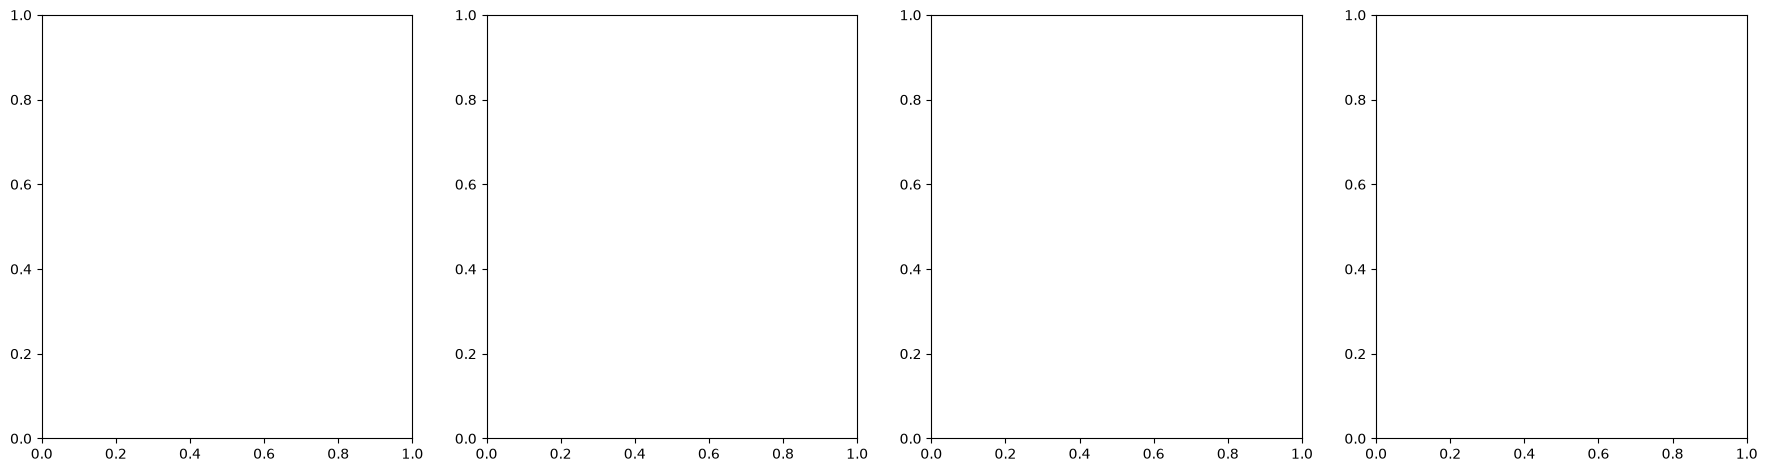

In [12]:
fig, eixos = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, k in zip(eixos, [1, 3, 7, 15]):
    margem_x = (X1[:, 0].max() - X1[:, 0].min()) * 0.15
    margem_y = (X1[:, 1].max() - X1[:, 1].min()) * 0.15
    gx, gy = np.meshgrid(
        np.linspace(X1[:, 0].min() - margem_x, X1[:, 0].max() + margem_x, 200),
        np.linspace(X1[:, 1].min() - margem_y, X1[:, 1].max() + margem_y, 200))
    Z = prever_lote(X1, y1, np.column_stack([gx.ravel(), gy.ravel()]), k).reshape(gx.shape)
    ax.contourf(gx, gy, Z, levels=[0.5, 1.5, 2.5, 3.5], cmap=matplotlib_cmap(), alpha=0.28)
    for c in sorted(set(y1)):
        ax.scatter(X1[y1 == c, 0], X1[y1 == c, 1], s=45, label=f"C{c}")
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Renda Mensal (R$)")
    ax.legend(fontsize=8)
eixos[0].set_ylabel("Gasto Mensal (R$)")
fig.suptitle("Exercício 1 — Efeito do valor de k na fronteira entre os grupos", fontsize=15)
fig.tight_layout()
fig.savefig("fig_ex1_fronteiras.png", dpi=110)
plt.show()